# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** Lina María Castro
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 💳 **Inclusión financiera y pobreza: ¿el acceso al crédito formal está asociado con mejores condiciones de bienestar en los hogares rurales de Colombia?**

**Notebook 2 de 2: modelos de aprendizaje supervisado**

**Integrantes:** Isabella Ramirez Santamaria, Kevin Stiven Albarracin González, Julián Eduardo Lizarazo Caceres, Juan Felipe Pacheco Gómez.



| Modelo | Pregunta | Variable objetivo | Población |
|---|---|---|---|
| **Modelo 1** | ¿Qué características de partida explican quién tiene crédito formal? ¿La ruralidad pesa por sí sola cuando se compara a personas con el mismo ingreso? | `credito_formal` (1 = tiene crédito formal) | Todos los adultos (5.532) |
| **Modelo 2** | En los hogares rurales, ¿tener crédito formal se asocia con más resiliencia ante un choque de ingreso cuando se controla por ingreso, activos, educación y empleo? | `aguanta_un_mes_o_mas` (1 = podría vivir un mes o más sin ingresos) | Adultos de municipios rurales y rurales dispersos |

Los dos son problemas de **clasificación binaria**. En cada uno se comparan los cuatro clasificadores vistos en clase (regresión logística, árbol de decisión, Random Forest y XGBoost) con `GridSearchCV` y validación cruzada de 5 pliegues, y el mejor se evalúa una sola vez en el conjunto de prueba.

**Importante:** los modelos miden **asociaciones**, no efectos causales. Los datos son de corte transversal y quienes tienen crédito son distintos desde antes de obtenerlo .

---
## 1. Librerías y configuración

In [ ]:
import os

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocesamiento
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Métricas e interpretación
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score
import shap

# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

# Configuraciones para una mejor visualización
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Semilla única para todos los procesos aleatorios
SEMILLA = 42

os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/tables', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'outputs/figures/{nombre}.png', dpi=150, bbox_inches='tight')

---
## 2. Carga de la base procesada

In [ ]:
RUTA_BASE = 'data/processed/base_inclusion_financiera_2022.csv'
assert os.path.exists(RUTA_BASE), 'Primero se debe correr notebooks/01_limpieza_eda.ipynb, que genera esta base.'

df = pd.read_csv(RUTA_BASE)
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (5532, 59)


,cod_mpio,municipio,cod_dpto,departamento,region,ruralidad,rural,area,peso,credito_formal,credito_informal,solicito_credito,credito_negado,gota_a_gota,uso_consumo,uso_productivo,uso_vivienda_vehiculo,ahorro_formal,ahorro_digital,ahorro_informal,no_ahorra,ingreso_rango,ingreso_hogar,ingreso_smmlv,log_ingreso,segmento_ingreso,gasto_hogar,gasta_mas_que_gana,indice_bienestar,meses_resiliencia,aguanta_un_mes_o_mas,indice_activos,sexo,mujer,edad,jefe_hogar,educacion,educ_superior,actividad,ocupado,cuenta_propia,trabaja_agro,ingreso_irregular,estrato,menores_hogar,ocupados_hogar,ocupados_estables,usa_internet,cocina_con_lena,barrera: No le gusta endeudarse,barrera: Lo considera costoso,barrera: No se ajusta a sus necesidades,barrera: No lo considera útil,barrera: Reportado en centrales de riesgo,barrera: No tiene garantías,barrera: Ingresos bajos / no puede responder,barrera: No entiende cómo funciona,barrera: Piden muchos requisitos,barrera: No tiene historial crediticio
0,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"11,450.00",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,1.00,0.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","1,250,000.00",1.00,41.67,0.25,0.00,4.00,Femenino,1.00,35,0.00,Secundaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,1.00,2,2.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
1,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"4,024.34",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,0.00,1.00,Entre 750.001 y 1.000.000,"875,000.00",0.88,13.68,"0,5-1 SM","375,000.00",0.00,29.17,1.00,1.00,6.00,Femenino,1.00,48,1.00,Primaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,1.00,2,0.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
2,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"10,369.24",1.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","625,000.00",0.00,35.42,1.00,1.00,4.00,Femenino,1.00,69,1.00,Primaria,0.00,Oficios del hogar,0.00,0.00,0.00,0.00,1.00,0,1.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11001,"Bogotá, D.C.",11,"Bogotá, D.C.",Centro Oriente,Ciudades y aglomeraciones,0,Ciudades e intermedios,"6,544.89",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,1.00,0.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","625,000.00",0.00,47.92,18.00,1.00,2.00,Femenino,1.00,41,1.00,Secundaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,NaN,1,1.00,1.00,1.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
4,76001,Cali,76,Valle Del Cauca,Pacífico,Ciudades y aglomeraciones,0,Ciudades e intermedios,"33,366.72",1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,Entre 3.000.001 y 4.000.000,"3,500,000.00",3.50,15.07,> 2 SM,"6,000,000.00",1.00,41.67,0.25,0.00,6.00,Femenino,1.00,32,1.00,Tecnólogos,1.00,Oficios del hogar,0.00,0.00,0.00,0.00,4.00,3,2.00,2.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Variables explicativas

Se usan solo **características de partida** de la persona y su hogar, es decir, variables que existen antes de pedir un crédito. No se incluyen variables del propio proceso de crédito (si pidió, si le negaron, en qué entidad), porque eso sería fuga de información (*data leakage*): el modelo "sabría" la respuesta.

La educación viene como categoría ordenada; se convierte a un número de 0 (ninguna) a 6 (posgrado), igual que en el notebook 1.

In [ ]:
orden_educacion = ['Ninguno', 'Primaria', 'Secundaria', 'Técnico', 'Tecnólogos', 'Universitarios', 'Posgrado']
df['educ_orden'] = df['educacion'].map({nivel: i for i, nivel in enumerate(orden_educacion)})

# Variables continuas u ordinales: se imputan con la mediana y se estandarizan
vars_continuas = ['ingreso_smmlv', 'indice_activos', 'edad', 'educ_orden', 'estrato', 'menores_hogar']

# Variables binarias (0/1): se imputan con la moda y no se estandarizan, para que su coeficiente se lea como "tener la característica"
vars_binarias = ['ocupado', 'cuenta_propia', 'trabaja_agro', 'ingreso_irregular', 'mujer', 'jefe_hogar',
                 'usa_internet', 'cocina_con_lena']

nombres_legibles = {
    'ingreso_smmlv': 'Ingreso del hogar (SM)', 'indice_activos': 'Índice de activos', 'edad': 'Edad',
    'educ_orden': 'Nivel educativo', 'estrato': 'Estrato', 'menores_hogar': 'Menores en el hogar',
    'ocupado': 'Ocupado', 'cuenta_propia': 'Cuenta propia', 'trabaja_agro': 'Trabaja en el agro',
    'ingreso_irregular': 'Ingreso irregular', 'mujer': 'Mujer', 'jefe_hogar': 'Jefe de hogar',
    'usa_internet': 'Usa internet', 'cocina_con_lena': 'Cocina con leña',
    'ruralidad_Intermedio': 'Municipio intermedio', 'ruralidad_Rural': 'Municipio rural',
    'ruralidad_Rural disperso': 'Municipio rural disperso',
    'credito_formal': 'Crédito formal', 'credito_informal': 'Crédito informal', 'ahorro_formal': 'Ahorro formal'
}

# Faltantes por variable (vienen de respuestas "No sabe / No responde" del notebook 1)
df[vars_continuas + vars_binarias].isna().sum().to_frame('faltantes').T

,ingreso_smmlv,indice_activos,edad,educ_orden,estrato,menores_hogar,ocupado,cuenta_propia,trabaja_agro,ingreso_irregular,mujer,jefe_hogar,usa_internet,cocina_con_lena
faltantes,230,0,0,4,243,0,0,0,0,388,0,0,28,3


**Decisión sobre faltantes:** el ingreso, el estrato y la regularidad del ingreso tienen entre 4 % y 7 % de faltantes. Eliminar esas filas reduciría la muestra en cerca de 14 %, así que se imputan con `SimpleImputer` **dentro del pipeline**: la mediana (o la moda) se calcula solo con los datos de entrenamiento de cada pliegue, lo que evita fuga de información hacia el conjunto de prueba.

### 2.2 Preprocesador y funciones de apoyo

Se sigue la estructura del notebook de clases desbalanceadas: un `ColumnTransformer` con un transformador por tipo de variable, y un `Pipeline` por modelo. Las funciones evitan repetir el mismo código en los dos modelos.

In [ ]:
def crear_preprocesador(continuas, binarias, categoricas):
    transformadores = [
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), continuas),
        ('bin', SimpleImputer(strategy='most_frequent'), binarias),
    ]
    if categoricas:
        transformadores.append(('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categoricas))
    return ColumnTransformer(transformadores, verbose_feature_names_out=False)


def entrenar_modelos(preprocesador, X_train, y_train):

    conteo = y_train.value_counts()
    peso_positivos = conteo[0] / conteo[1]

    candidatos = {
        'Regresión Logística': (
            LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEMILLA),
            {'model__C': [0.01, 0.1, 1, 10]}),
        'Árbol de Decisión': (
            DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
            {'model__max_depth': [3, 4, 5, 6, 8], 'model__min_samples_leaf': [10, 25, 50]}),
        'Random Forest': (
            RandomForestClassifier(class_weight='balanced', random_state=SEMILLA, n_jobs=-1),
            {'model__n_estimators': [200, 400], 'model__max_depth': [4, 6, 8], 'model__min_samples_leaf': [5, 15]}),
        'XGBoost': (
            XGBClassifier(objective='binary:logistic', eval_metric='logloss', scale_pos_weight=peso_positivos,
                          random_state=SEMILLA, n_jobs=1),
            {'model__n_estimators': [150, 300], 'model__learning_rate': [0.03, 0.08], 'model__max_depth': [2, 3, 4]}),
    }

    busquedas = {}
    for nombre, (modelo, grilla) in candidatos.items():
        pipeline = Pipeline([('preprocessor', preprocesador), ('model', modelo)])
        grid = GridSearchCV(pipeline, param_grid=grilla, cv=5, scoring='roc_auc', n_jobs=-1, verbose=1)
        grid.fit(X_train, y_train)
        busquedas[nombre] = grid
        print(f"{nombre}: AUC-ROC en CV = {grid.best_score_:.4f} | {grid.best_params_}\n")
    return busquedas


def comparar_en_prueba(busquedas, X_test, y_test):

    filas = []
    for nombre, grid in busquedas.items():
        proba = grid.best_estimator_.predict_proba(X_test)[:, 1]
        pred = grid.best_estimator_.predict(X_test)
        filas.append({'Modelo': nombre, 'AUC_CV': grid.best_score_, 'AUC_prueba': roc_auc_score(y_test, proba),
                      'F1_clase_1_prueba': f1_score(y_test, pred)})
    return pd.DataFrame(filas).sort_values('AUC_CV', ascending=False).reset_index(drop=True)


def graficar_roc(busquedas, X_test, y_test, titulo, archivo):
    plt.figure(figsize=(8, 6))
    for nombre, grid in busquedas.items():
        proba = grid.best_estimator_.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, proba)
        plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Clasificador aleatorio')
    plt.xlabel('Tasa de Falsos Positivos')
    plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
    plt.title(titulo)
    plt.legend(loc='lower right', fontsize=9)
    guardar(archivo)
    plt.show()


def matriz_confusion(modelo, X_test, y_test, etiquetas, titulo, archivo):
    pred = modelo.predict(X_test)
    print(classification_report(y_test, pred, target_names=etiquetas))
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=[f'Pred: {e}' for e in etiquetas], yticklabels=[f'Real: {e}' for e in etiquetas])
    plt.ylabel('Etiqueta Real')
    plt.xlabel('Etiqueta Predicha')
    plt.title(titulo)
    guardar(archivo)
    plt.show()


def odds_ratios_logit(grid_logit):

    modelo = grid_logit.best_estimator_
    nombres = modelo.named_steps['preprocessor'].get_feature_names_out()
    coef = modelo.named_steps['model'].coef_[0]
    tabla = pd.DataFrame({'Variable': [nombres_legibles.get(n, n) for n in nombres], 'Coeficiente': coef,
                          'Odds_Ratio': np.exp(coef)})
    tabla['Cambio_en_odds_%'] = (tabla['Odds_Ratio'] - 1) * 100
    return tabla.sort_values('Odds_Ratio', ascending=False).reset_index(drop=True)


def valores_shap(grid_arbol, X_test):

    modelo = grid_arbol.best_estimator_
    X_transformado = modelo.named_steps['preprocessor'].transform(X_test)
    nombres = [nombres_legibles.get(n, n) for n in modelo.named_steps['preprocessor'].get_feature_names_out()]
    explicador = shap.TreeExplainer(modelo.named_steps['model'])
    valores = np.array(explicador.shap_values(X_transformado))
    if valores.ndim == 3:            # Random Forest devuelve una matriz por clase: se toma la clase 1
        valores = valores[:, :, 1]
    return valores, pd.DataFrame(X_transformado, columns=nombres)

---
## 3. Modelo 1: ¿quién tiene crédito formal?

**Variable objetivo:** `credito_formal`. **Población:** los 5.532 adultos de la base, porque la pregunta incluye si la ruralidad pesa por sí sola, y para eso se necesita comparar con las ciudades. La ruralidad del municipio entra como variable categórica (la categoría de referencia es *Ciudades y aglomeraciones*).

In [ ]:
vars_categoricas_m1 = ['ruralidad']
X1 = df[vars_continuas + vars_binarias + vars_categoricas_m1]
y1 = df['credito_formal'].astype(int)

print('Distribución de la variable objetivo:')
print(y1.value_counts(normalize=True).round(3))

Distribución de la variable objetivo:
credito_formal
0   0.78
1   0.23
Name: proportion, dtype: float64


Solo el 22,5 % tiene crédito formal: las clases están desbalanceadas (cerca de 78/22). Por eso, como en el notebook de clases desbalanceadas:
- se divide con `stratify` para mantener la proporción en entrenamiento y prueba,
- se usa `class_weight='balanced'` (y `scale_pos_weight` en XGBoost) para que los errores en la clase minoritaria pesen más,
- la métrica de selección es el **AUC-ROC** y no la exactitud, que sería engañosa (un modelo que diga siempre "no tiene crédito" acertaría el 78 %).

In [ ]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=SEMILLA, stratify=y1)
print(f'Entrenamiento: {X1_train.shape} | Prueba: {X1_test.shape}')
print(f'Proporción con crédito en entrenamiento: {y1_train.mean():.3f} | en prueba: {y1_test.mean():.3f}')

preprocesador_m1 = crear_preprocesador(vars_continuas, vars_binarias, vars_categoricas_m1)

Entrenamiento: (4425, 15) | Prueba: (1107, 15)
Proporción con crédito en entrenamiento: 0.225 | en prueba: 0.225


### 3.1 Búsqueda de hiperparámetros con validación cruzada

In [ ]:
busquedas_m1 = entrenar_modelos(preprocesador_m1, X1_train, y1_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


Regresión Logística: AUC-ROC en CV = 0.7073 | {'model__C': 0.1}

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Árbol de Decisión: AUC-ROC en CV = 0.6767 | {'model__max_depth': 4, 'model__min_samples_leaf': 50}

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Random Forest: AUC-ROC en CV = 0.7081 | {'model__max_depth': 8, 'model__min_samples_leaf': 15, 'model__n_estimators': 400}

Fitting 5 folds for each of 12 candidates, totalling 60 fits


XGBoost: AUC-ROC en CV = 0.7055 | {'model__learning_rate': 0.08, 'model__max_depth': 2, 'model__n_estimators': 300}



### 3.2 Comparación de modelos

In [ ]:
resultados_m1 = comparar_en_prueba(busquedas_m1, X1_test, y1_test)
resultados_m1

,Modelo,AUC_CV,AUC_prueba,F1_clase_1_prueba
0,Random Forest,0.71,0.73,0.47
1,Regresión Logística,0.71,0.73,0.48
2,XGBoost,0.71,0.73,0.48
3,Árbol de Decisión,0.68,0.69,0.45


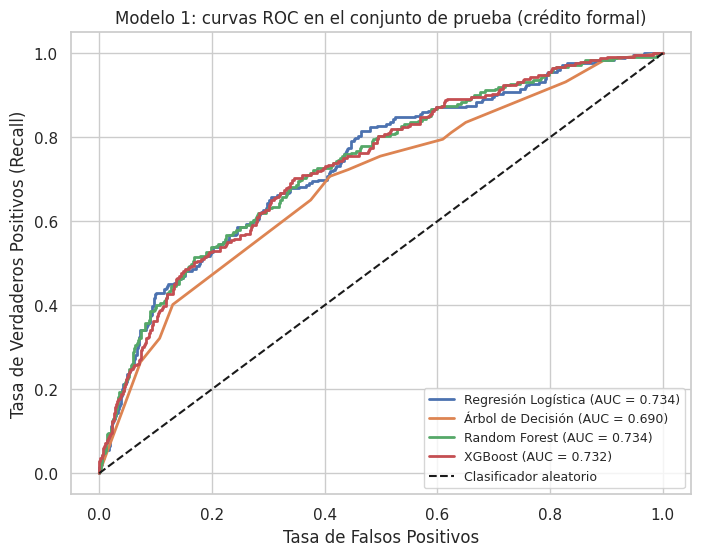

In [ ]:
graficar_roc(busquedas_m1, X1_test, y1_test, 'Modelo 1: curvas ROC en el conjunto de prueba (crédito formal)', '10_roc_modelo1')

Modelo campeón (mayor AUC en validación cruzada): Random Forest
              precision    recall  f1-score   support

 Sin crédito       0.86      0.72      0.79       858
 Con crédito       0.39      0.61      0.47       249

    accuracy                           0.70      1107
   macro avg       0.63      0.67      0.63      1107
weighted avg       0.76      0.70      0.72      1107



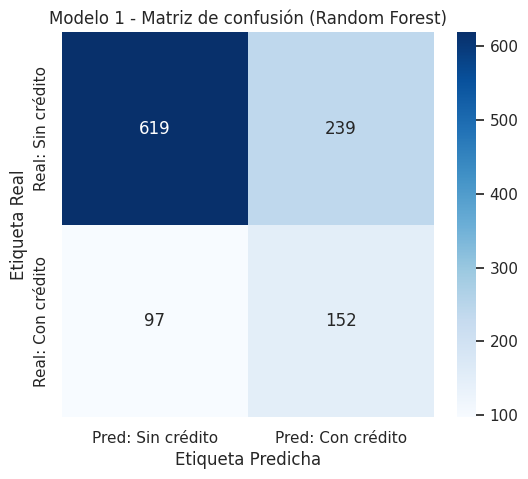

In [ ]:
ganador_m1 = resultados_m1.loc[0, 'Modelo']
print(f'Modelo campeón (mayor AUC en validación cruzada): {ganador_m1}')
matriz_confusion(busquedas_m1[ganador_m1].best_estimator_, X1_test, y1_test, ['Sin crédito', 'Con crédito'],
                 f'Modelo 1 - Matriz de confusión ({ganador_m1})', '11_matriz_confusion_modelo1')

**Qué muestra:** Random Forest gana por muy poco en la validación cruzada (AUC de 0,708), casi empatado con la regresión logística (0,707) y XGBoost (0,705). En el conjunto de prueba los tres llegan a 0,73, muy cerca del resultado de la validación cruzada, así que no hay sobreajuste. El árbol de decisión individual queda último (0,677), como se esperaba frente a los ensambles.

Un AUC de 0,73 quiere decir que si se toma al azar una persona con crédito formal y otra sin crédito, el modelo le asigna una probabilidad mayor a la que sí tiene crédito en el 73 % de los casos. Con el umbral de 0,5, el modelo identifica al 61 % de quienes tienen crédito (recall), y de los que marca como "con crédito", el 39 % lo tiene (precisión).

**Qué significa:** las características de partida explican una parte importante del acceso, pero no todo. Quedan factores que la encuesta no mide, como el historial con el banco o la oferta de entidades en el municipio. Como la regresión logística rinde prácticamente igual que los ensambles y es mucho más fácil de interpretar, se usa para leer la dirección y el tamaño de cada asociación, y SHAP sobre Random Forest se usa para confirmar la importancia de las variables.

### 3.3 Interpretación: odds ratios de la regresión logística

In [ ]:
or_m1 = odds_ratios_logit(busquedas_m1['Regresión Logística'])
or_m1

,Variable,Coeficiente,Odds_Ratio,Cambio_en_odds_%
0,Municipio rural,0.49,1.64,63.88
1,Ocupado,0.45,1.57,57.06
2,Municipio rural disperso,0.45,1.57,56.67
3,Usa internet,0.43,1.54,53.50
4,Ingreso del hogar (SM),0.34,1.41,41.07
5,Edad,0.34,1.41,40.90
6,Índice de activos,0.27,1.30,30.38
7,Nivel educativo,0.21,1.24,23.53
8,Trabaja en el agro,0.09,1.10,9.71
9,Jefe de hogar,0.08,1.08,8.34


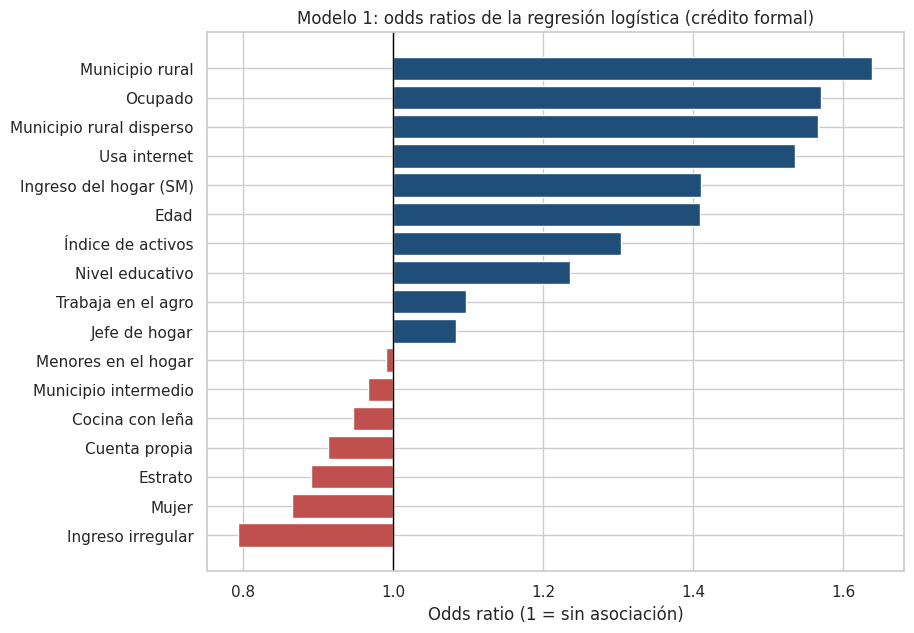

In [ ]:
plt.figure(figsize=(9, 7))
colores = ['#1f4e79' if v > 1 else '#c0504d' for v in or_m1['Odds_Ratio']]
plt.barh(or_m1['Variable'], or_m1['Odds_Ratio'] - 1, left=1, color=colores)
plt.axvline(1, color='black', lw=1)
plt.gca().invert_yaxis()
plt.xlabel('Odds ratio (1 = sin asociación)')
plt.title('Modelo 1: odds ratios de la regresión logística (crédito formal)')
guardar('12_odds_ratios_modelo1')
plt.show()

**Cómo se leen:** para una variable continua, el odds ratio es el cambio en los *odds* de tener crédito cuando la variable aumenta una desviación estándar, manteniendo lo demás constante. Para una binaria o una categoría, es el cambio frente a no tener la característica (o frente a vivir en *Ciudades y aglomeraciones*).

**Qué muestra:**
- **Ruralidad:** comparando personas con el mismo ingreso, activos, educación y empleo, vivir en un municipio rural multiplica los odds de tener crédito formal por 1,64, y en uno rural disperso por 1,57, frente a las ciudades. En los municipios intermedios el odds ratio es 0,97, prácticamente igual a las ciudades.
- **Capacidad de pago:** estar ocupado (1,57), una desviación estándar más de ingreso (1,41), de edad (1,41), de activos (1,30) y de educación (1,24) aumentan los odds de tener crédito.
- **Conectividad:** usar internet los multiplica por 1,54.
- **Riesgo percibido:** tener ingresos irregulares los reduce un 21 % (0,79) y ser mujer un 14 % (0,87).

**Qué significa:** el modelo confirma de forma multivariada el hallazgo del EDA. La desventaja rural en el acceso al crédito **no se debe a la ruralidad en sí**, sino a que los hogares rurales tienen menos ingreso, menos empleo y menos conectividad. Una vez se comparan personas con las mismas condiciones, la ruralidad se asocia con **más** crédito formal, lo que es consistente con el papel de las cooperativas, a las que acude el 27,6 % de los solicitantes rurales según el EDA. La penalización a los ingresos irregulares es la señal del racionamiento por información de Stiglitz y Weiss (1981): al prestamista le cuesta evaluar el riesgo de quien no tiene un ingreso estable.

### 3.4 Interpretación: importancia y dirección de las variables con SHAP

In [ ]:

arboles_m1 = resultados_m1[resultados_m1['Modelo'].isin(['Random Forest', 'XGBoost'])].iloc[0]['Modelo']
print('Modelo de árboles interpretado con SHAP:', arboles_m1)
shap_m1, X1_test_transf = valores_shap(busquedas_m1[arboles_m1], X1_test)

importancia_m1 = pd.Series(np.abs(shap_m1).mean(axis=0), index=X1_test_transf.columns).sort_values(ascending=False)
importancia_m1.to_frame('SHAP_medio_absoluto')

Modelo de árboles interpretado con SHAP: Random Forest


,SHAP_medio_absoluto
Ingreso del hogar (SM),0.06
Edad,0.04
Índice de activos,0.04
Ocupado,0.03
Nivel educativo,0.03
Ingreso irregular,0.02
Mujer,0.02
Usa internet,0.02
Municipio rural,0.01
Menores en el hogar,0.01


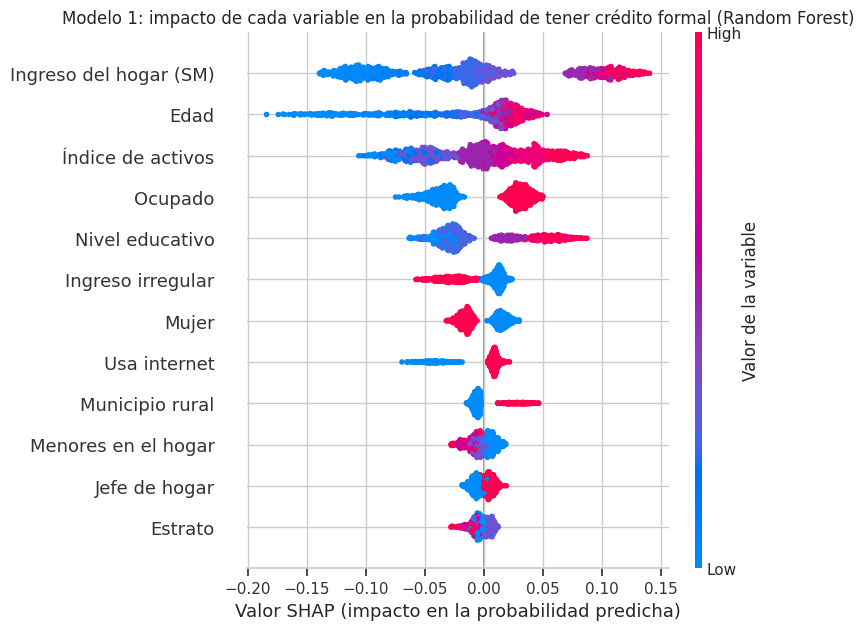

In [ ]:
shap.summary_plot(shap_m1, X1_test_transf, show=False, max_display=12)
plt.title(f'Modelo 1: impacto de cada variable en la probabilidad de tener crédito formal ({arboles_m1})')
plt.xlabel('Valor SHAP (impacto en la probabilidad predicha)')
plt.gcf().axes[-1].set_ylabel('Valor de la variable')
guardar('13_shap_modelo1')
plt.show()

**Cómo leer el gráfico SHAP:** cada punto es una persona del conjunto de prueba. Hacia la derecha, la variable **aumenta** la probabilidad de tener crédito formal; hacia la izquierda, la disminuye. El color indica el valor de la variable (rojo = alto, azul = bajo).

**Qué muestra:** en Random Forest la variable más importante es el **ingreso del hogar**, seguida de la edad, los activos, estar ocupado y la educación. Los valores altos de ingreso (puntos rojos) empujan hacia la derecha y los bajos hacia la izquierda. La ruralidad del municipio tiene una importancia baja.

**Qué significa:** los dos métodos de interpretación coinciden en que el acceso al crédito formal depende sobre todo de la **capacidad de pago** y del colateral (ingreso, activos y empleo), y no del territorio. Para la política pública esto quiere decir que ampliar la oferta en zonas rurales no basta si los hogares no tienen ingresos estables con los cuales responder.

---
## 4. Modelo 2: ¿el crédito formal se asocia con más resiliencia en los hogares rurales?

**Variable objetivo:** `aguanta_un_mes_o_mas` (1 si la persona podría vivir un mes o más con sus ahorros o vendiendo activos si deja de recibir ingresos). En el EDA, esta medida de comportamiento fue la que mostró diferencias claras entre quienes tienen y no tienen crédito, mientras que el índice de bienestar percibido casi no cambiaba y tiene una consistencia interna moderada (alfa de Cronbach de 0,63).

**Población:** adultos de municipios rurales y rurales dispersos, que es la población de la pregunta de investigación.

**Variables explicativas:** las mismas características de partida del Modelo 1, más tres variables financieras: crédito formal, crédito informal y ahorro formal. La pregunta clave es si el **crédito formal** sigue siendo relevante cuando el modelo ya conoce el ingreso, los activos, la educación y el empleo.

In [ ]:
rural = df[(df['rural'] == 1) & df['aguanta_un_mes_o_mas'].notna()].copy()

vars_financieras = ['credito_formal', 'credito_informal', 'ahorro_formal']
vars_binarias_m2 = vars_financieras + vars_binarias
vars_categoricas_m2 = ['ruralidad']
X2 = rural[vars_continuas + vars_binarias_m2 + vars_categoricas_m2]
y2 = rural['aguanta_un_mes_o_mas'].astype(int)

print('Personas en la población rural con respuesta de resiliencia:', len(rural))
print(y2.value_counts(normalize=True).round(3))

Personas en la población rural con respuesta de resiliencia: 1204
aguanta_un_mes_o_mas
1   0.64
0   0.36
Name: proportion, dtype: float64


In [ ]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=SEMILLA, stratify=y2)
print(f'Entrenamiento: {X2_train.shape} | Prueba: {X2_test.shape}')

preprocesador_m2 = crear_preprocesador(vars_continuas, vars_binarias_m2, vars_categoricas_m2)

Entrenamiento: (963, 18) | Prueba: (241, 18)


### 4.1 Búsqueda de hiperparámetros con validación cruzada

In [ ]:
busquedas_m2 = entrenar_modelos(preprocesador_m2, X2_train, y2_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


Regresión Logística: AUC-ROC en CV = 0.6397 | {'model__C': 0.01}

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Árbol de Decisión: AUC-ROC en CV = 0.6205 | {'model__max_depth': 5, 'model__min_samples_leaf': 50}

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Random Forest: AUC-ROC en CV = 0.6376 | {'model__max_depth': 8, 'model__min_samples_leaf': 15, 'model__n_estimators': 200}

Fitting 5 folds for each of 12 candidates, totalling 60 fits


XGBoost: AUC-ROC en CV = 0.6244 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 150}



### 4.2 Comparación de modelos

In [ ]:
resultados_m2 = comparar_en_prueba(busquedas_m2, X2_test, y2_test)
resultados_m2

,Modelo,AUC_CV,AUC_prueba,F1_clase_1_prueba
0,Regresión Logística,0.64,0.62,0.64
1,Random Forest,0.64,0.61,0.63
2,XGBoost,0.62,0.60,0.58
3,Árbol de Decisión,0.62,0.55,0.61


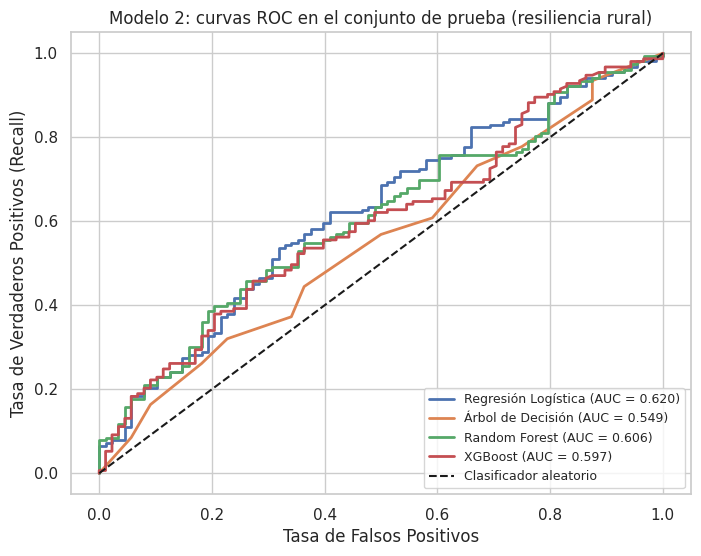

In [ ]:
graficar_roc(busquedas_m2, X2_test, y2_test, 'Modelo 2: curvas ROC en el conjunto de prueba (resiliencia rural)', '14_roc_modelo2')

Modelo campeón (mayor AUC en validación cruzada): Regresión Logística
                 precision    recall  f1-score   support

Menos de un mes       0.46      0.64      0.53        88
   Un mes o más       0.73      0.57      0.64       153

       accuracy                           0.59       241
      macro avg       0.60      0.60      0.59       241
   weighted avg       0.63      0.59      0.60       241



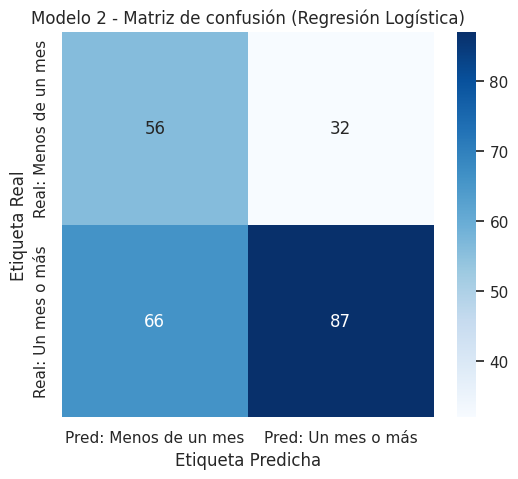

In [ ]:
ganador_m2 = resultados_m2.loc[0, 'Modelo']
print(f'Modelo campeón (mayor AUC en validación cruzada): {ganador_m2}')
matriz_confusion(busquedas_m2[ganador_m2].best_estimator_, X2_test, y2_test, ['Menos de un mes', 'Un mes o más'],
                 f'Modelo 2 - Matriz de confusión ({ganador_m2})', '15_matriz_confusion_modelo2')

**Qué muestra:** en este modelo gana la regresión logística, con un AUC de 0,640 en validación cruzada y de 0,620 en prueba, seguida muy de cerca por Random Forest (0,638). El poder predictivo es **modesto**: el modelo identifica al 57 % de quienes sí aguantarían un mes o más sin ingresos, con una precisión del 73 %.

**Qué significa:** la resiliencia de un hogar rural depende en buena parte de cosas que la encuesta no observa, como ahorros no declarados, redes familiares o la posibilidad de vender una cosecha. Por eso el objetivo de este modelo no es predecir con precisión, sino medir **cuánto pesa el crédito formal frente a las demás características** cuando se analizan todas juntas.

### 4.3 Interpretación: odds ratios de la regresión logística

In [ ]:
or_m2 = odds_ratios_logit(busquedas_m2['Regresión Logística'])
or_m2

,Variable,Coeficiente,Odds_Ratio,Cambio_en_odds_%
0,Ingreso del hogar (SM),0.26,1.30,30.20
1,Ocupado,0.13,1.14,14.35
2,Nivel educativo,0.12,1.12,12.31
3,Crédito formal,0.08,1.09,8.59
4,Cuenta propia,0.08,1.08,8.37
5,Índice de activos,0.07,1.07,7.46
6,Trabaja en el agro,0.07,1.07,7.22
7,Usa internet,0.07,1.07,6.99
8,Ahorro formal,0.05,1.05,4.66
9,Municipio rural disperso,0.03,1.03,2.98


**Qué muestra:** el ingreso del hogar es la variable con mayor asociación (una desviación estándar más multiplica los odds de aguantar un mes o más por 1,30), seguido de estar ocupado (1,14) y la educación (1,12). El crédito formal aparece en cuarto lugar (1,09). Ser mujer (0,87) y la edad (0,90) se asocian con menos resiliencia.

**Ojo:** la búsqueda escogió `C = 0,01`, una regularización fuerte que **encoge todos los coeficientes hacia cero**. Sirve para predecir mejor, pero subestima el tamaño de cada asociación. Por eso, para medir el tamaño de la asociación del crédito, la siguiente sección estima una logística sin penalización.

### 4.4 ¿Cuánto de la asociación con el crédito es selección?

Se compara el odds ratio del crédito formal en dos regresiones logísticas sobre toda la población rural:
1. **Sin controles:** solo el crédito formal.
2. **Con controles:** crédito formal más todas las características de partida.

Si el odds ratio cae mucho al agregar los controles, buena parte de la diferencia en resiliencia se explica por quiénes obtienen crédito (selección). Para medir la incertidumbre se usa un **bootstrap** de 500 remuestreos con reemplazo: el intervalo del 95 % va del percentil 2,5 al 97,5 de los odds ratios estimados. Se usa `penalty=None` para que el coeficiente no se encoja por la regularización.

In [ ]:
def or_credito(datos, controles):
    variables = ['credito_formal'] + controles
    pre = crear_preprocesador([v for v in variables if v in vars_continuas],
                              [v for v in variables if v not in vars_continuas and v != 'ruralidad'],
                              ['ruralidad'] if 'ruralidad' in variables else [])
    modelo = Pipeline([('preprocessor', pre), ('model', LogisticRegression(penalty=None, max_iter=5000))])
    modelo.fit(datos[variables], datos['aguanta_un_mes_o_mas'].astype(int))
    nombres = list(modelo.named_steps['preprocessor'].get_feature_names_out())
    return np.exp(modelo.named_steps['model'].coef_[0][nombres.index('credito_formal')])

controles = vars_continuas + ['credito_informal', 'ahorro_formal'] + vars_binarias + ['ruralidad']
rng = np.random.default_rng(SEMILLA)
filas = []
for etiqueta, ctrl in [('Sin controles', []), ('Con controles', controles)]:
    estimado = or_credito(rural, ctrl)
    remuestreos = [or_credito(rural.iloc[rng.integers(0, len(rural), len(rural))], ctrl) for _ in range(500)]
    filas.append({'Especificación': etiqueta, 'Odds_Ratio': estimado,
                  'IC95_inferior': np.percentile(remuestreos, 2.5), 'IC95_superior': np.percentile(remuestreos, 97.5)})
seleccion = pd.DataFrame(filas)
seleccion

,Especificación,Odds_Ratio,IC95_inferior,IC95_superior
0,Sin controles,1.67,1.26,2.16
1,Con controles,1.34,1.01,1.79


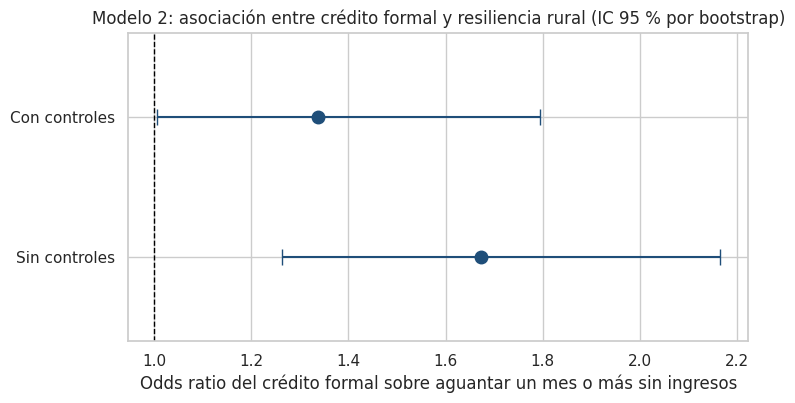

In [ ]:
plt.figure(figsize=(8, 4))
plt.errorbar(seleccion['Odds_Ratio'], seleccion['Especificación'],
             xerr=[seleccion['Odds_Ratio'] - seleccion['IC95_inferior'], seleccion['IC95_superior'] - seleccion['Odds_Ratio']],
             fmt='o', color='#1f4e79', capsize=6, markersize=9)
plt.axvline(1, color='black', lw=1, ls='--')
plt.xlabel('Odds ratio del crédito formal sobre aguantar un mes o más sin ingresos')
plt.ylim(-0.6, 1.6)
plt.title('Modelo 2: asociación entre crédito formal y resiliencia rural (IC 95 % por bootstrap)')
guardar('16_seleccion_credito_resiliencia')
plt.show()

**Qué muestra:** sin controles, tener crédito formal multiplica los odds de aguantar un mes o más sin ingresos por 1,67 (IC 95 %: 1,26 a 2,16). Es la diferencia que vimos en el EDA: 72 % de los rurales con crédito frente a 61 % de los que no tienen. Al controlar por ingreso, activos, educación, empleo y las demás características, el odds ratio baja a 1,34 (IC 95 %: 1,01 a 1,79).

**Qué significa:** cerca de **la mitad de la ventaja** asociada al crédito (de +67 % a +34 % en los odds) se explica por quiénes lo obtienen, es decir, por **selección**. La asociación que queda sigue siendo positiva, pero el límite inferior del intervalo está prácticamente en 1, así que la evidencia es débil. Con estos datos no se puede afirmar que el crédito cause más resiliencia: también puede ser al revés, que los hogares con más colchón financiero sean los que se atreven a endeudarse.

### 4.5 Interpretación: importancia y dirección de las variables con SHAP

In [ ]:
arboles_m2 = resultados_m2[resultados_m2['Modelo'].isin(['Random Forest', 'XGBoost'])].iloc[0]['Modelo']
print('Modelo de árboles interpretado con SHAP:', arboles_m2)
shap_m2, X2_test_transf = valores_shap(busquedas_m2[arboles_m2], X2_test)

importancia_m2 = pd.Series(np.abs(shap_m2).mean(axis=0), index=X2_test_transf.columns).sort_values(ascending=False)
importancia_m2.to_frame('SHAP_medio_absoluto')

Modelo de árboles interpretado con SHAP: Random Forest


,SHAP_medio_absoluto
Ingreso del hogar (SM),0.05
Ocupado,0.03
Edad,0.03
Mujer,0.02
Nivel educativo,0.02
Usa internet,0.02
Índice de activos,0.01
Menores en el hogar,0.01
Crédito formal,0.01
Ingreso irregular,0.01


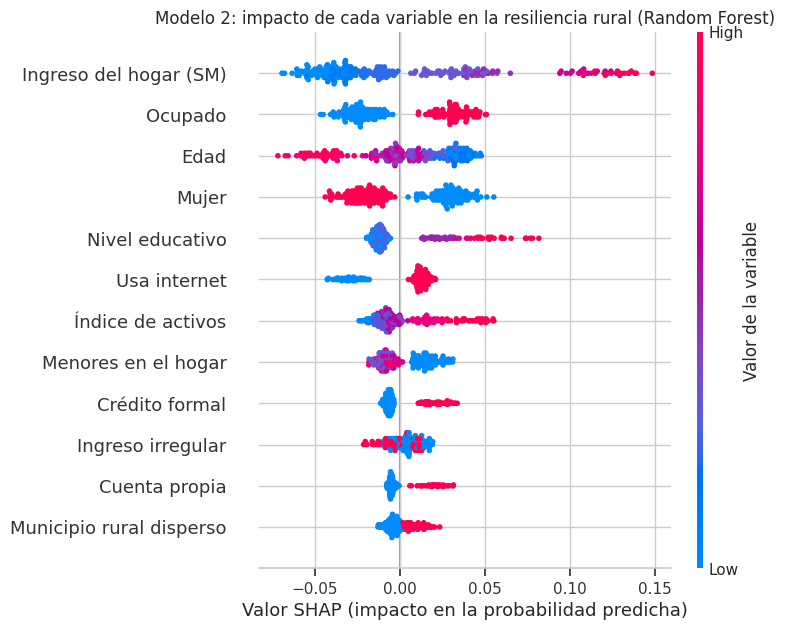

In [ ]:
shap.summary_plot(shap_m2, X2_test_transf, show=False, max_display=12)
plt.title(f'Modelo 2: impacto de cada variable en la resiliencia rural ({arboles_m2})')
plt.xlabel('Valor SHAP (impacto en la probabilidad predicha)')
plt.gcf().axes[-1].set_ylabel('Valor de la variable')
guardar('17_shap_modelo2')
plt.show()

**Qué muestra:** en Random Forest, las variables que más mueven la probabilidad de aguantar un mes o más sin ingresos son el ingreso del hogar, estar ocupado, la edad, ser mujer y la educación. El crédito formal aparece en el noveno lugar, con una importancia pequeña, y el ahorro formal y el crédito informal casi no pesan.

**Qué significa:** los dos enfoques llevan a la misma conclusión. En los hogares rurales, la capacidad de enfrentar un choque de ingreso depende sobre todo del **nivel y la estabilidad del ingreso**, y el crédito formal agrega poco una vez se tiene eso en cuenta. Esto responde la pregunta abierta del EDA: la inclusión crediticia rural está llegando principalmente a los hogares que ya estaban en mejores condiciones.

---
## 5. Conclusiones de los modelos

1. **Acceso (Modelo 1):** el crédito formal depende de la capacidad de pago (ingreso, activos, empleo, educación) y de la conectividad. Con las mismas características, vivir en un municipio rural **no reduce** las probabilidades de tener crédito: las aumenta (odds ratio de 1,64). La desventaja rural pasa por el ingreso.
2. **Bienestar (Modelo 2):** la asociación entre crédito formal y resiliencia rural se reduce a la mitad al controlar por las condiciones de partida (de 1,67 a 1,34) y queda en el límite de la significancia. El ingreso y el empleo son los que más explican la resiliencia.
3. **Modelos:** los ensambles no superan claramente a la regresión logística en ninguno de los dos problemas. Con variables de encuesta y relaciones casi monotónicas, el modelo más simple es igual de bueno y más interpretable.

---
## 6. Exportación de resultados

In [ ]:
with pd.ExcelWriter('outputs/tables/tablas_modelos.xlsx') as writer:
    resultados_m1.to_excel(writer, sheet_name='M1 comparacion', index=False)
    or_m1.to_excel(writer, sheet_name='M1 odds ratios', index=False)
    importancia_m1.to_frame('SHAP').to_excel(writer, sheet_name='M1 SHAP')
    resultados_m2.to_excel(writer, sheet_name='M2 comparacion', index=False)
    or_m2.to_excel(writer, sheet_name='M2 odds ratios', index=False)
    importancia_m2.to_frame('SHAP').to_excel(writer, sheet_name='M2 SHAP')
    seleccion.to_excel(writer, sheet_name='M2 seleccion', index=False)
    pd.DataFrame({n: g.best_params_ for n, g in {**{f'M1 {k}': v for k, v in busquedas_m1.items()},
                                                  **{f'M2 {k}': v for k, v in busquedas_m2.items()}}.items()}).T \
        .to_excel(writer, sheet_name='Hiperparametros')
print('Tablas guardadas en outputs/tables/tablas_modelos.xlsx')

Tablas guardadas en outputs/tables/tablas_modelos.xlsx


In [ ]:

from importlib.metadata import version
librerias = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'openpyxl', 'requests', 'scikit-learn', 'xgboost', 'shap']
with open('requirements.txt', 'w') as f:
    for lib in librerias:
        f.write(f'{lib}=={version(lib)}\n')
print(open('requirements.txt').read())

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3
openpyxl==3.1.5
requests==2.32.4
scikit-learn==1.6.1
xgboost==2.1.4
shap==0.48.0

